<a href="https://colab.research.google.com/github/shaswanthk/Webpage/blob/main/Legendary_pokemon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_csv("Pokemon Data.csv")

data.head(1)

,#,Name,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,45,49,49,65,65,45,1,False


In [ ]:
data['Type 2'].fillna(value='none', inplace=True)

/tmp/ipykernel_2502/3830226306.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['Type 2'].fillna(value='none', inplace=True)


<Axes: xlabel='Type 2'>

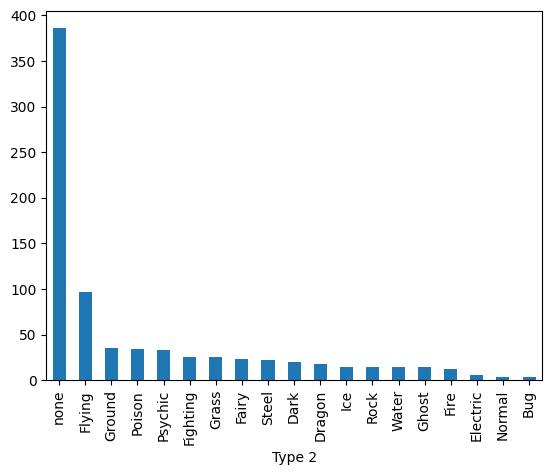

In [ ]:
data['Type 2'].value_counts().plot.bar()

<Axes: xlabel='Type 1'>

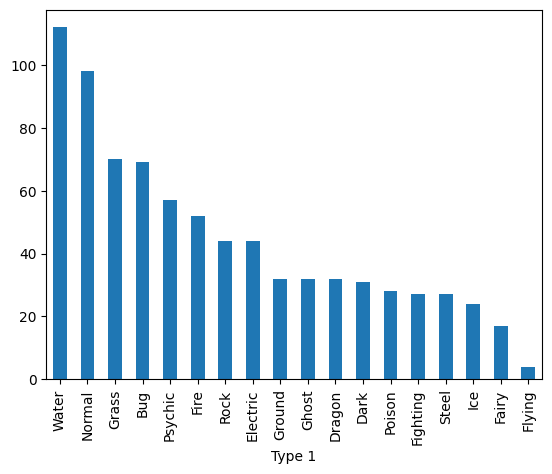

In [ ]:
data['Type 1'].value_counts().plot.bar()

<Axes: xlabel='Legendary'>

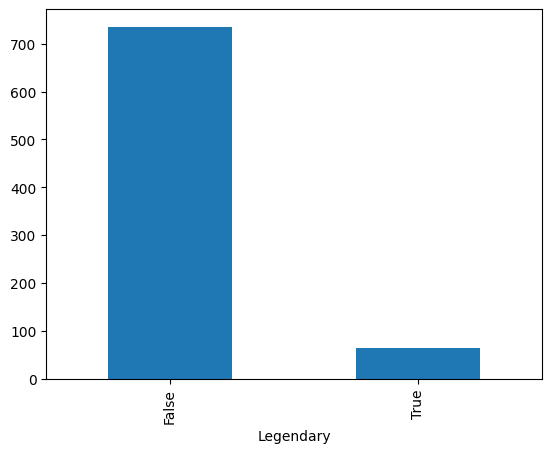

In [ ]:
data['Legendary'].value_counts().plot.bar()

In [ ]:
data['Type 1'].unique()

array(['Grass', 'Fire', 'Water', 'Bug', 'Normal', 'Poison', 'Electric',
       'Ground', 'Fairy', 'Fighting', 'Psychic', 'Rock', 'Ghost', 'Ice',
       'Dragon', 'Dark', 'Steel', 'Flying'], dtype=object)

In [ ]:
from sklearn.preprocessing import LabelEncoder

lb = LabelEncoder()
data['Legendary'] = lb.fit_transform(data['Legendary'])

In [ ]:
data.drop('Name', axis=1, inplace=True)

In [ ]:
data.head()

,#,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Grass,Poison,45,49,49,65,65,45,1,0
1,2,Grass,Poison,60,62,63,80,80,60,1,0
2,3,Grass,Poison,80,82,83,100,100,80,1,0
3,3,Grass,Poison,80,100,123,122,120,80,1,0
4,4,Fire,none,39,52,43,60,50,65,1,0


In [ ]:
data = pd.get_dummies(data)

In [ ]:
from sklearn.model_selection import train_test_split

y = data['Legendary']
X = data.drop('Legendary', axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [ ]:
from sklearn.linear_model import LogisticRegression
LogReg = LogisticRegression(max_iter=1000)
LogReg.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [ ]:
from sklearn.metrics import accuracy_score
ypred1 = LogReg.predict(X_test)
accuracy_score(y_test, ypred1)

0.95

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

error_rates = []

In [ ]:
for a in range(1,40):
  k = a
  knn = KNeighborsClassifier(n_neighbors = k)
  knn.fit(X_train, y_train)
  preds = knn.predict(X_test)

  error_rates.append(np.mean(preds != y_test))

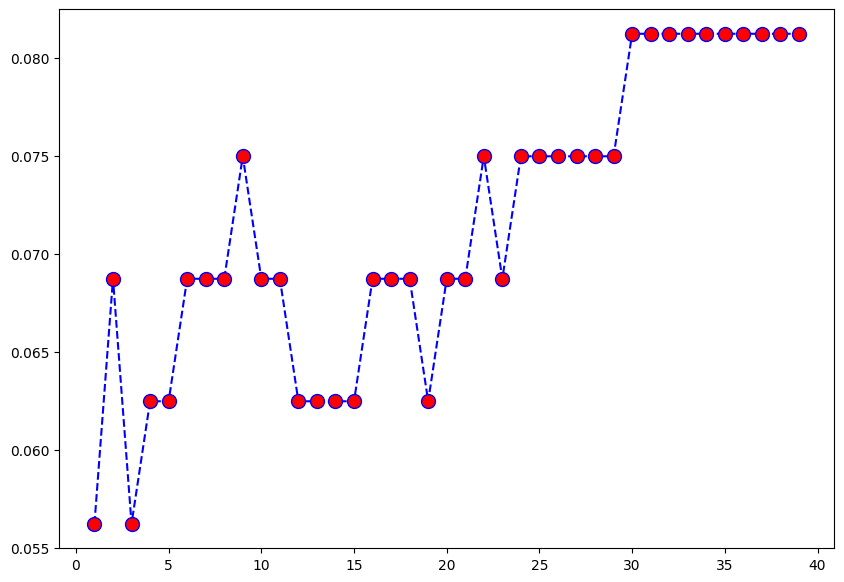

In [ ]:
plt.figure(figsize=(10,7))
plt.plot(range(1,40), error_rates, color='blue', linestyle='dashed', marker='o', markerfacecolor='red', markersize=10)

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=4)

knn_model.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=4)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

clf_model = DecisionTreeClassifier()
clf_model.fit(X_train, y_train)

DecisionTreeClassifier()